In [2]:
from google.colab import files

uploaded = files.upload()

Saving TEAM_12.zip to TEAM_12 (1).zip


In [27]:
from math import log, sqrt, pi
import numpy as np
import matplotlib.pyplot as plt

seed = 42     #	Random Number Generator

def myRandom():
  global seed
  a = 1664525
  c = 1013904223
  m = 2**32
  seed = (a * seed + c) % m
  return seed / m

def myUniform(a, b):
  return a + (b - a) * myRandom()

def gaussian(mu, sigma, n=1):
  g = []
  while len(g) < n:
    u1 = myUniform(-1, 1)
    u2 = myUniform(-1, 1)
    s = u1*u1 + u2*u2
    if 0 < s < 1:
      k = sqrt(-2 * log(s) / s)
      x = u1 * k
      y = u2 * k
      g.append(mu + sigma * x)
      if len(g) < n:
        g.append(mu + sigma * y)
  return g if n > 1 else g[0]

def generate_gaussian(mean, covariance):   #Generate one 2-D point from a Gaussian
# Uses Cholesky-style transform + Marsaglia polar
  a = covariance[0][0]
  b = covariance[0][1]
  c = covariance[1][1]
  z1 = gaussian(0, 1)
  z2 = gaussian(0, 1)
  x1 = mean[0] + sqrt(a) * z1
  x2 = mean[1] + (b / sqrt(a)) * z1 + sqrt(c - (b*b)/a) * z2
  return [x1, x2]

#	Generate data
def generate_data(N, weights, means, covariances):
  data = []
  component_labels = []
  for _ in range(N):
    u = myRandom()
    if u < weights[0]:
      component = 0
    elif u < weights[0] + weights[1]:
      component = 1
    else:
      component = 2
    point = generate_gaussian(means[component], covariances[component])
    data.append(point)
    component_labels.append(component)
  return data, component_labels

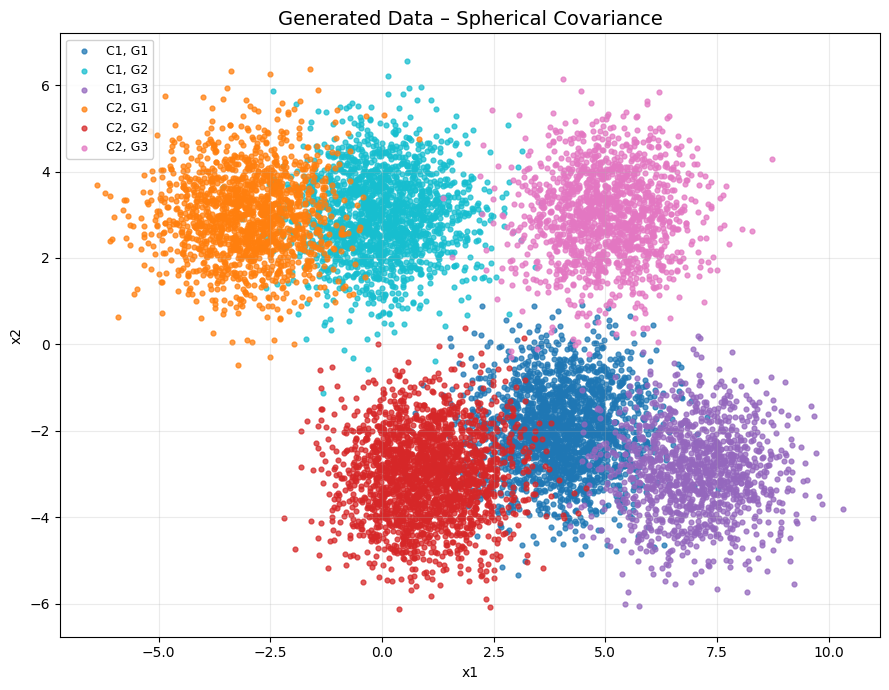

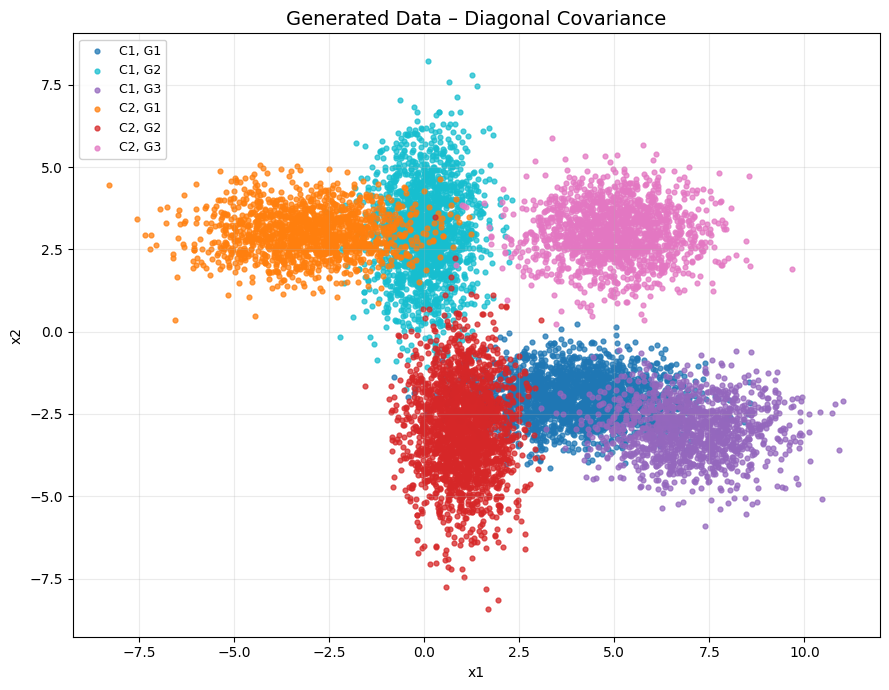

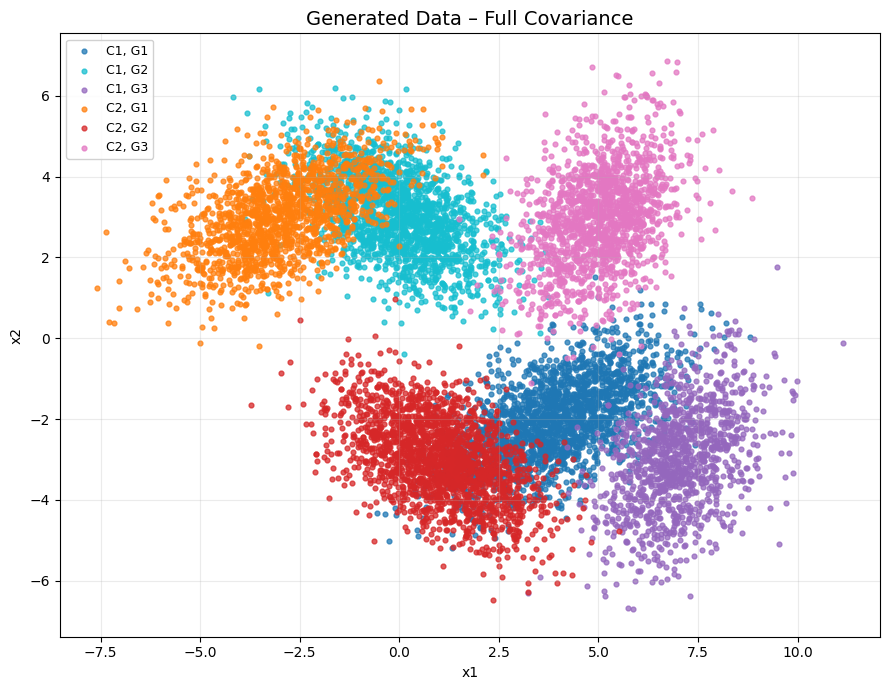

In [28]:
#	Parameters
N = 5000
K = 3

weights1 = [0.40, 0.35, 0.25]
means1 = [[4, -2], [0, 3], [7, -3]]
weights2 = [0.30, 0.40, 0.30]
means2 = [[-3, 3], [1, -3], [5, 3]]

covariance_types = { "Spherical": [
[[1, 0], [0, 1]],
[[1, 0], [0, 1]],
[[1, 0], [0, 1]]
],
"Diagonal": [
[[2, 0], [0, 0.5]],
[[0.5, 0], [0, 2]],
[[1.5, 0], [0, 0.7]]
],
"Full": [
[[2, 0.8], [0.8, 1]],
[[1.5, -0.6], [-0.6, 1]],
[[1, 0.5], [0.5, 1.5]]
]
}

generated_data = {}

colors = {
(1, 0): "#1f77b4",
(1, 1): "#17becf",
(1, 2): "#9467bd",
(2, 0): "#ff7f0e",
(2, 1): "#d62728",
(2, 2): "#e377c2",
}

for name, covariances in covariance_types.items():
  class1, labels1 = generate_data(N, weights1, means1, covariances)
  class2, labels2 = generate_data(N, weights2, means2, covariances)

  generated_data[name] = { "Class 1": class1,
  "Class 2": class2,
  "Labels 1": labels1,
  "Labels 2": labels2
  }
  class1_np = np.array(class1)
  class2_np = np.array(class2)

  plt.figure(figsize=(9, 7))
  for comp in range(3):
    mask = np.array(labels1) == comp
    plt.scatter(class1_np[mask, 0], class1_np[mask, 1], c=colors[(1, comp)], s=12, alpha=0.75, label=f"C1, G{comp+1}")
  for comp in range(3):
    mask = np.array(labels2) == comp
    plt.scatter(class2_np[mask, 0], class2_np[mask, 1], c=colors[(2, comp)], s=12, alpha=0.75, label=f"C2, G{comp+1}")
  plt.title(f"Generated Data – {name} Covariance", fontsize=14)
  plt.xlabel("x1")
  plt.ylabel("x2")
  plt.legend(loc="upper left", fontsize=9, framealpha=0.9)
  plt.grid(True, alpha=0.25)
  plt.tight_layout()
  plt.show()

In [42]:
def logsumexp(a, axis=1):
    maximum = np.max(a, axis=axis, keepdims=True)
    result = maximum + np.log(np.sum(np.exp(a - maximum), axis=axis, keepdims=True))
    return np.squeeze(result, axis=axis)

class GMM:
    def __init__(self, K=3, max_iter=100, tol=1e-4, reg=1e-5):
        self.K = K
        self.max_iter = max_iter
        self.tol = tol
        self.reg = reg

    def gaussian_log_probability(self, X, mean, covariance):
        d = X.shape[1]
        diff = X - mean
        sign, logdet = np.linalg.slogdet(covariance)
        if sign <= 0:
            raise ValueError("Covariance matrix is not positive definite")
        solved = np.linalg.solve(
            covariance, diff.T
        ).T
        quadratic = np.sum(diff * solved, axis=1)
        return -0.5 * (d * np.log(2 * np.pi) + logdet + quadratic)

    def score_samples(self, X):
        probabilities = []
        for k in range(self.K):
            value = (np.log(self.weights[k]) + self.gaussian_log_probability(X, self.means[k], self.covariances[k]))
            probabilities.append(value)
        probabilities = np.column_stack(probabilities)
        return logsumexp(probabilities, axis=1)

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        N, D = X.shape
        rng = np.random.default_rng(42)
        indices = rng.choice(N, self.K, replace=False)
        self.means = X[indices].copy()
        global_cov = np.cov(X, rowvar=False)
        global_cov += self.reg * np.eye(D)
        self.covariances = np.array([global_cov.copy() for _ in range(self.K)])
        self.weights = np.ones(self.K) / self.K
        self.log_likelihoods = []
        previous_ll = -np.inf

        for iteration in range(self.max_iter):
            # E-step
            log_joint = []
            for k in range(self.K):
                value = (
                    np.log(self.weights[k])
                    + self.gaussian_log_probability(
                        X,
                        self.means[k],
                        self.covariances[k]
                    )
                )
                log_joint.append(value)
            log_joint = np.column_stack(log_joint)
            log_norm = logsumexp(log_joint, axis=1)
            responsibilities = np.exp(
                log_joint - log_norm[:, None]
            )
            current_ll = np.mean(log_norm)
            self.log_likelihoods.append(current_ll)

            # M-step
            Nk = responsibilities.sum(axis=0) + 1e-10
            self.weights = Nk / N
            self.means = (responsibilities.T @ X) / Nk[:, None]
            new_covariances = []
            for k in range(self.K):
                diff = X - self.means[k]
                weighted_diff = (diff * responsibilities[:, k:k+1])
                covariance = (weighted_diff.T @ diff) / Nk[k]
                covariance += self.reg * np.eye(D)
                new_covariances.append(covariance)
            self.covariances = np.array(new_covariances)
            # Convergence check
            if abs(current_ll - previous_ll) < self.tol:
                break
            previous_ll = current_ll
        return self

In [43]:
datasets = {}
rng = np.random.default_rng(44)
for name in covariance_types:

    class1 = np.asarray(generated_data[name]["Class 1"])
    class2 = np.asarray(generated_data[name]["Class 2"])

    index1 = rng.permutation(len(class1))
    index2 = rng.permutation(len(class2))

    split1 = int(0.8 * len(class1))
    split2 = int(0.8 * len(class2))

    train1 = class1[index1[:split1]]
    test1 = class1[index1[split1:]]

    train2 = class2[index2[:split2]]
    test2 = class2[index2[split2:]]

    datasets[name] = {
        "train1": train1,
        "test1": test1,
        "train2": train2,
        "test2": test2
    }

In [44]:
part1_results = {}
for name in covariance_types:

    train1 = datasets[name]["train1"]
    train2 = datasets[name]["train2"]

    test1 = datasets[name]["test1"]
    test2 = datasets[name]["test2"]

    # Train separate GMM models
    model1 = GMM(K=3)
    model2 = GMM(K=3)

    model1.fit(train1)
    model2.fit(train2)

    # Class 1 testing
    scores1 = np.column_stack([model1.score_samples(test1), model2.score_samples(test1)])
    predictions1 = np.argmax(scores1, axis=1)

    # Class 2 testing
    scores2 = np.column_stack([model1.score_samples(test2), model2.score_samples(test2)])
    predictions2 = np.argmax(scores2, axis=1)

    # Confusion matrix
    cm = np.zeros((2, 2), dtype=int)
    for prediction in predictions1:
        cm[0, prediction] += 1

    for prediction in predictions2:
        cm[1, prediction] += 1

    accuracy = np.trace(cm) / np.sum(cm) * 100
    part1_results[name] = {
        "confusion_matrix": cm,
        "accuracy": accuracy,
        "model1": model1,
        "model2": model2
    }

    print("=" * 45)
    print("Covariance:", name)
    print("Confusion Matrix:")
    print(cm)
    print(f"Accuracy: {accuracy:.2f}%")
    print()

Covariance: Spherical
Confusion Matrix:
[[952  48]
 [ 57 943]]
Accuracy: 94.75%

Covariance: Diagonal
Confusion Matrix:
[[942  58]
 [ 44 956]]
Accuracy: 94.90%

Covariance: Full
Confusion Matrix:
[[909  91]
 [ 87 913]]
Accuracy: 91.10%



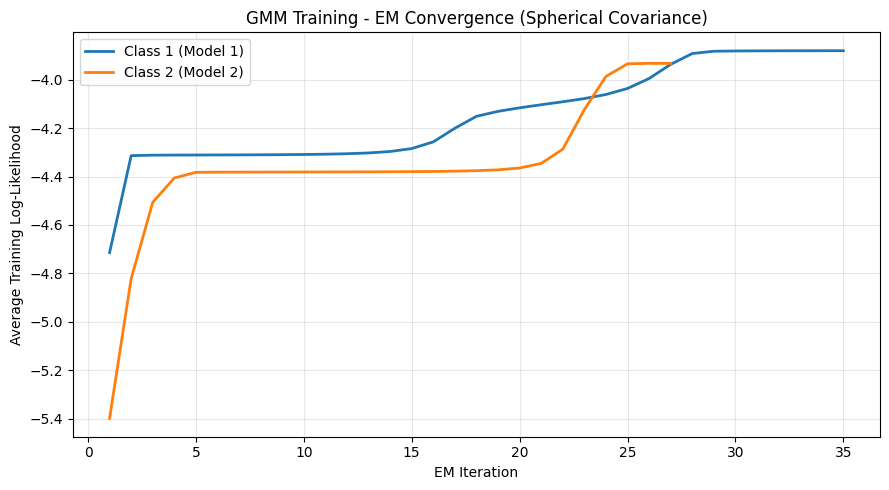

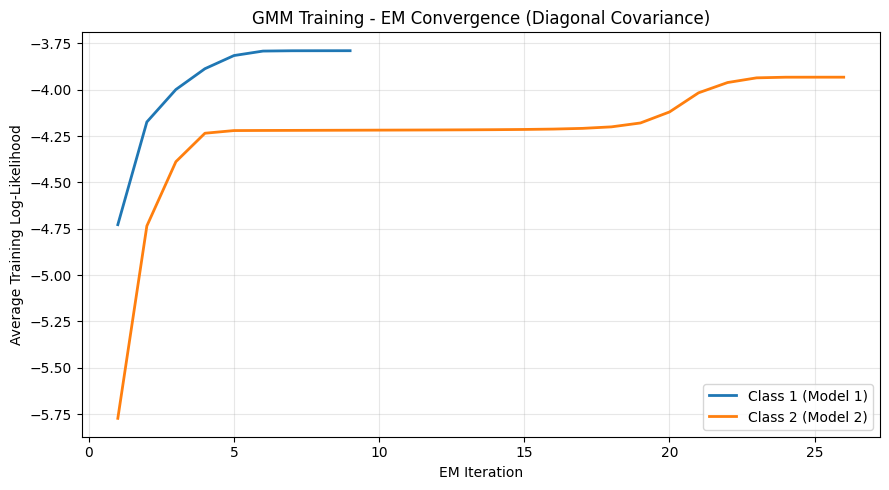

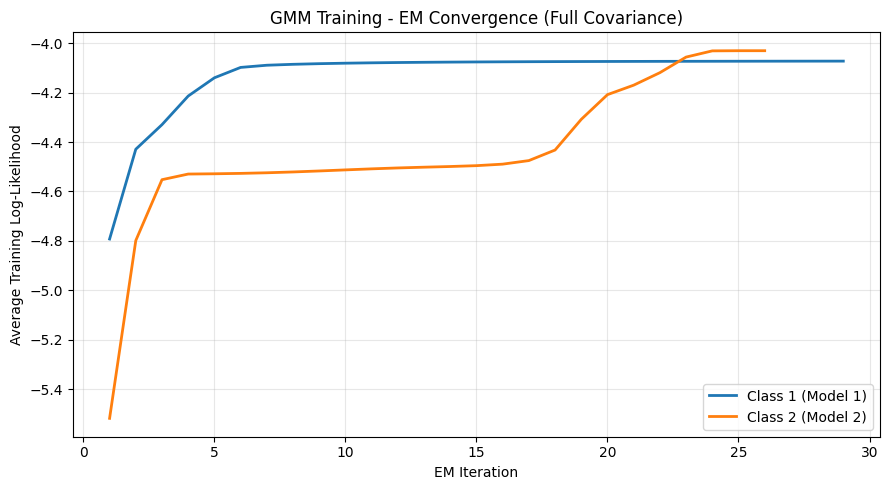

In [41]:
# EM Convergence Graph
covariance_names = ["Spherical", "Diagonal", "Full"]
for cov_name in covariance_names:
    class1_ll = part1_results[cov_name]["model1"].log_likelihoods
    class2_ll = part1_results[cov_name]["model2"].log_likelihoods
    plt.figure(figsize=(9, 5))
    plt.plot(
        range(1, len(class1_ll) + 1),
        class1_ll,
        label="Class 1 (Model 1)",
        linewidth=2
    )
    plt.plot(
        range(1, len(class2_ll) + 1),
        class2_ll,
        label="Class 2 (Model 2)",
        linewidth=2
    )
    plt.title(f"GMM Training - EM Convergence ({cov_name} Covariance)")
    plt.xlabel("EM Iteration")
    plt.ylabel("Average Training Log-Likelihood")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [48]:
import os
import zipfile
zip_name = next(name for name in uploaded if name.lower().endswith(".zip"))
with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall("/content")
team_folder = None
for root, dirs, files_list in os.walk("/content"):
    if os.path.basename(root).upper() == "TEAM_12":
        if all(
            os.path.isdir(os.path.join(root, split))
            for split in ["train", "dev", "test"]
        ):
            team_folder = root
            break

if team_folder is None:
    raise FileNotFoundError("TEAM_12 folder was not found")

print("Dataset location:", team_folder)
print("Train:", os.listdir(os.path.join(team_folder, "train")))
print("Dev:", os.listdir(os.path.join(team_folder, "dev")))
print("Test:", os.listdir(os.path.join(team_folder, "test")))

Dataset location: /content/TEAM_12
Train: ['6', '1', '9']
Dev: ['6', '1', '9']
Test: ['6', '1', '9']


Digit 1: (5383, 28, 28)
Digit 6: (4752, 28, 28)
Digit 9: (4776, 28, 28)


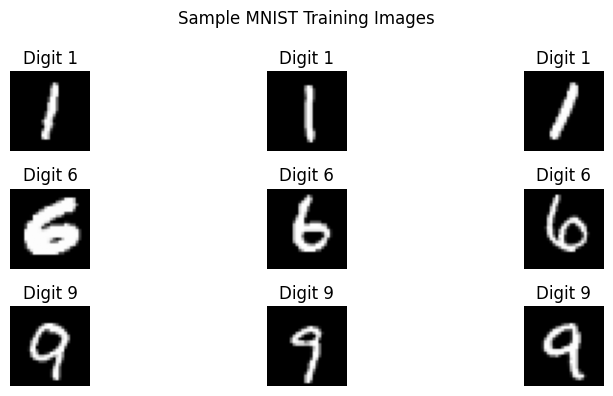

In [59]:
from PIL import Image
digits = [1, 6, 9]
def load_digit_images(split):
    class_images = []
    for digit in digits:
        folder = os.path.join(team_folder, split, str(digit))
        images = []
        for filename in sorted(os.listdir(folder)):
            filepath = os.path.join(folder, filename)
            try:
                with Image.open(filepath) as image:
                    image = image.convert("L")
                    image = image.resize((28, 28))
                    images.append(np.asarray(image, dtype=np.float32) / 255.0)
            except Exception:
                continue
        if len(images) == 0:
            raise ValueError(f"No readable images found for digit {digit}")
        class_images.append(np.stack(images))
    return class_images

train_images = load_digit_images("train")
test_images = load_digit_images("test")

for digit, images in zip(digits, train_images):
    print(f"Digit {digit}:",images.shape)

plt.figure(figsize=(9, 4))
for class_index, digit in enumerate(digits):
    for i in range(3):
        plt.subplot(3, 3, class_index * 3 + i + 1)
        plt.imshow(train_images[class_index][i], cmap="gray")
        plt.title(f"Digit {digit}")
        plt.axis("off")
plt.suptitle("Sample MNIST Training Images")
plt.tight_layout()
plt.show()


Training GMM for digit 1
Training samples: 5383
EM iterations: 22
Weights: [0.55297322 0.08954127 0.35748551]
Training completed.

Training GMM for digit 6
Training samples: 4752
EM iterations: 33
Weights: [0.30765994 0.40832826 0.2840118 ]
Training completed.

Training GMM for digit 9
Training samples: 4776
EM iterations: 22
Weights: [0.32803716 0.20563474 0.4663281 ]
Training completed.


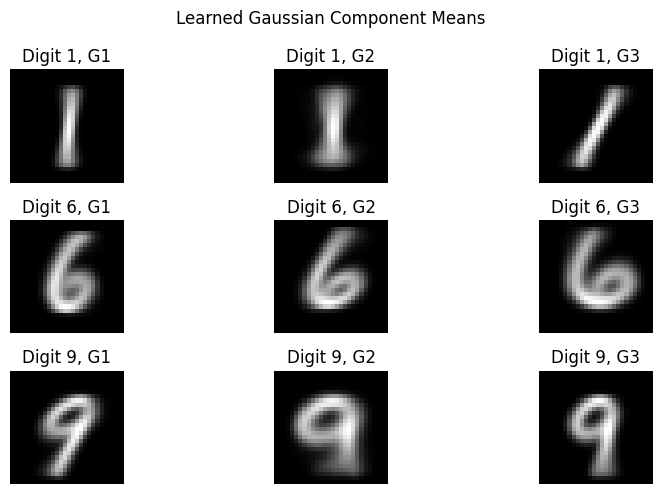

Digit order: [1, 6, 9]

Confusion Matrix
Rows = Actual digits
Columns = Predicted digits
[[1087   21   27]
 [   7  947    4]
 [  16    4  989]]

Overall Test Accuracy: 97.45%
CLASSIFICATION PERFORMANCE
Digit 1
Correct predictions: 1087
Total test images: 1135
Recall: 95.77%

Digit 6
Correct predictions: 947
Total test images: 958
Recall: 98.85%

Digit 9
Correct predictions: 989
Total test images: 1009
Recall: 98.02%



In [69]:
class DiagonalGMM:
    def __init__(self, K=3, max_iter=100, tol=1e-4, reg=1e-4):
        self.K = K
        self.max_iter = max_iter
        self.tol = tol
        self.reg = reg

    def component_log_probability(self, X):
        diff = X[:, None, :] - self.means[None, :, :]
        value = (np.log(self.weights)[None, :] - 0.5 * np.sum(np.log(2 * np.pi * self.variances) + (diff ** 2) / self.variances, axis=2))
        return value

    def score_samples(self, X):
        log_joint = self.component_log_probability(X)
        return logsumexp(log_joint, axis=1)

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        N, D = X.shape
        rng = np.random.default_rng(42)
        indices = rng.choice(N, self.K, replace=False)
        self.means = X[indices].copy()
        global_variance = np.var(X, axis=0) + self.reg
        self.variances = np.tile(global_variance,(self.K, 1))
        self.weights = np.ones(self.K) / self.K
        self.log_likelihoods = []
        previous_ll = -np.inf

        for iteration in range(self.max_iter):
            log_joint = self.component_log_probability(X)
            log_norm = logsumexp(log_joint, axis=1)
            responsibilities = np.exp(log_joint - log_norm[:, None])
            current_ll = np.mean(log_norm)
            self.log_likelihoods.append(current_ll)
            Nk = responsibilities.sum(axis=0) + 1e-10
            self.weights = Nk / N
            self.means = (responsibilities.T @ X) / Nk[:, None]
            self.variances = ((responsibilities.T @ (X ** 2)) / Nk[:, None] - self.means ** 2)
            self.variances = np.maximum(self.variances, self.reg)
            if abs(current_ll - previous_ll) < self.tol:
                break
            previous_ll = current_ll
        return self

K = 3
mnist_models = []
for digit, X in zip(digits, mnist_train):
    print(f"\nTraining GMM for digit {digit}")
    model = DiagonalGMM(K=K, max_iter=100, tol=1e-4, reg=1e-4)
    model.fit(X)
    mnist_models.append(model)
    print("Training samples:", len(X))
    print("EM iterations:", len(model.log_likelihoods))
    print("Weights:", model.weights)
    print("Training completed.")

plt.figure(figsize=(9, 5))
for class_index, (digit, model) in enumerate(zip(digits, mnist_models)):
    for k in range(K):
        plt.subplot(3, K, class_index * K + k + 1)
        plt.imshow(model.means[k].reshape(28, 28), cmap="gray")
        plt.title(f"Digit {digit}, G{k+1}")
        plt.axis("off")
plt.suptitle("Learned Gaussian Component Means")
plt.tight_layout()
plt.show()

mnist_confusion = np.zeros((3, 3), dtype=int)
mnist_predictions = []
mnist_scores = []
for true_class, X in enumerate(mnist_test):
    scores = np.column_stack([model.score_samples(X)for model in mnist_models])
    predictions = np.argmax(scores, axis=1)
    mnist_scores.append(scores)
    mnist_predictions.append(predictions)
    for predicted_class in predictions:
        mnist_confusion[true_class, predicted_class] += 1

print("Digit order:", digits)
print("\nConfusion Matrix")
print("Rows = Actual digits")
print("Columns = Predicted digits")
print(mnist_confusion)
accuracy = (np.trace(mnist_confusion) / np.sum(mnist_confusion)) * 100
print(f"\nOverall Test Accuracy: {accuracy:.2f}%")

print("CLASSIFICATION PERFORMANCE")
for i, digit in enumerate(digits):
    correct = mnist_confusion[i, i]
    total = mnist_confusion[i].sum()
    recall = (correct / total) * 100
    print(f"Digit {digit}")
    print(f"Correct predictions: {correct}")
    print(f"Total test images: {total}")
    print(f"Recall: {recall:.2f}%")
    print()

Actual 1 -> Predicted 6: 21 errors
Actual 1 -> Predicted 9: 27 errors
Actual 6 -> Predicted 1: 7 errors
Actual 6 -> Predicted 9: 4 errors
Actual 9 -> Predicted 1: 16 errors
Actual 9 -> Predicted 6: 4 errors


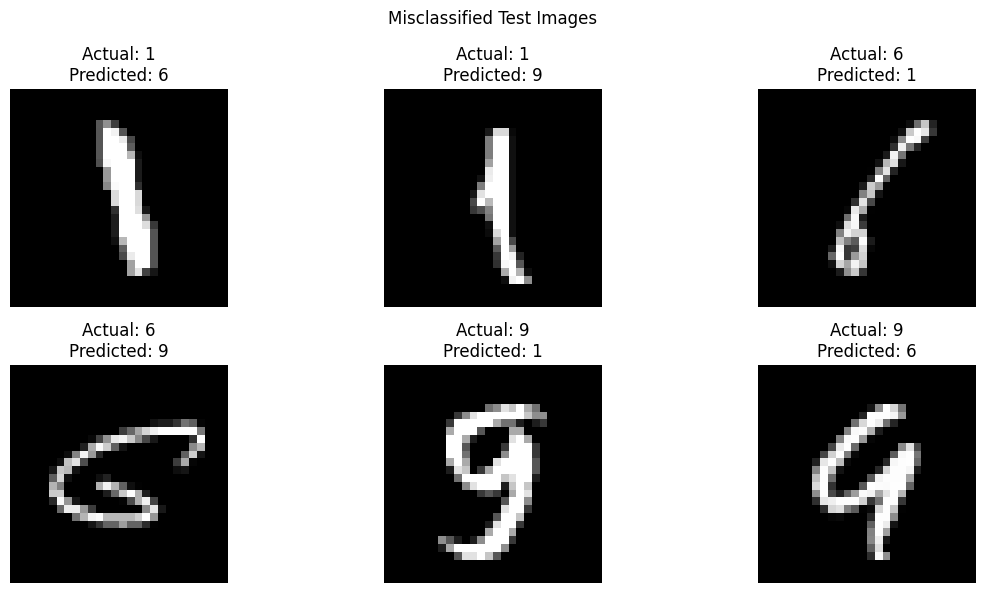

LIKELIHOOD MARGIN ANALYSIS
Actual digit: 1
Predicted digit: 6
Log-likelihood scores: [1610.77688152 1620.72301322 1131.75705964]
Likelihood margin: 9.946131691439405

Actual digit: 1
Predicted digit: 9
Log-likelihood scores: [1597.48155674 1166.68864954 1758.31842201]
Likelihood margin: 160.83686526923543

Actual digit: 6
Predicted digit: 1
Log-likelihood scores: [ 1921.25065118  1591.32116798 -2281.73199989]
Likelihood margin: 329.9294832033638

Actual digit: 6
Predicted digit: 9
Log-likelihood scores: [-1.98189836e+04  1.74900539e+01  8.85359225e+02]
Likelihood margin: 867.8691708518865

Actual digit: 9
Predicted digit: 1
Log-likelihood scores: [  1183.41345796 -11641.3073663    1179.11149056]
Likelihood margin: 4.301967394652593

Actual digit: 9
Predicted digit: 6
Log-likelihood scores: [ 676.90675177 1346.66399312 1276.50025358]
Likelihood margin: 70.16373954111873



In [70]:
error_examples = []
for true_class in range(3):
    predictions = mnist_predictions[true_class]
    for predicted_class in range(3):
        if true_class == predicted_class:
            continue

        indices = np.where(predictions == predicted_class )[0]
        if len(indices) > 0:
            error_examples.append(( true_class, predicted_class, indices[0]))
            print(
                f"Actual {digits[true_class]} "
                f"-> Predicted {digits[predicted_class]}: "
                f"{len(indices)} errors"
            )

if error_examples:
    rows = (len(error_examples) + 2) // 3
    plt.figure(figsize=(12, 3 * rows))
    for i, (true_class, predicted_class, image_index) in enumerate(error_examples):
        plt.subplot(rows, 3, i + 1)
        plt.imshow(test_images[true_class][image_index], cmap="gray")
        plt.title(f"Actual: {digits[true_class]}\n" f"Predicted: {digits[predicted_class]}")
        plt.axis("off")
    plt.suptitle("Misclassified Test Images")
    plt.tight_layout()
    plt.show()
else:
    print("No misclassified images.")

#LIKELIHOOD MARGIN
print("LIKELIHOOD MARGIN ANALYSIS")
for true_class in range(3):
    scores = mnist_scores[true_class]
    for predicted_class in range(3):
        if true_class == predicted_class:
            continue
        indices = np.where(mnist_predictions[true_class] == predicted_class)[0]
        if len(indices) > 0:
            index = indices[0]
            sample_scores = scores[index]
            sorted_scores = np.sort(sample_scores)
            margin = sorted_scores[-1] - sorted_scores[-2]

            print(f"Actual digit: {digits[true_class]}")
            print(f"Predicted digit: {digits[predicted_class]}")
            print("Log-likelihood scores:", sample_scores)
            print("Likelihood margin:", margin)
            print()